In [1]:
#LA API QUE SE REGISTRO SON LOS DATOS BASICOS DE LOS JUGADORES PARTICIPANTES
import requests
import pandas as pd

#SE HACE EL LLAMADO DE LA API DESDE UN APARTADO "SEGURO" COMO LO ES ESPN
base_url = "https://site.api.espn.com"
endpoint = "/apis/site/v2/sports/golf/pga/scoreboard?dates=20260920"
response = requests.get(base_url + endpoint)
print(response.status_code) # rectificamos que la aprobacion de la api fue la correcta 
data = response.json() # Convertimos la lectura a JSON para poder emepzar a interpretar 

print(data.keys()) # Miramos todo lo relacionado a lo que contiene el dataset

# ====================== EVENTO ======================================
#NOS ASEGURAMOS DEL TORNEO TRATADO - ESTE TORNEO TIENE BUENAS METRICAS Y OCURRIO HACE POCO
assert data["events"], "No hay eventos disponibles en la API en este momento" # Nos aseguramos de que haya al menos un torneo antes de indexar
evento = data["events"][0] # Ingreso al primer evento que se registro
print(evento["name"])# Tengo el nombre del evento
evento_id = evento["id"]
competicion = evento["competitions"][0]
jugador = competicion["competitors"]

# ================== CREACION DATAFRAME ============================
datos = []

for jugadores in jugador:

    nombre = jugadores["athlete"]["displayName"]

    # Score acumulado del jugador
    score = jugadores.get("score")

    # Posición
    posicion = jugadores.get("order")

    # Resultados por ronda
    linescores = jugadores.get("linescores", [])

    #Temporada
    season = evento["season"]["year"]

    ronda1 = linescores[0].get("value") if len(linescores) > 0 else None
    ronda2 = linescores[1].get("value") if len(linescores) > 1 else None
    ronda3 = linescores[2].get("value") if len(linescores) > 2 else None
    ronda4 = linescores[3].get("value") if len(linescores) > 3 else None


    datos.append(
        {
            "jugador": nombre,
            "posicion": posicion,
            "score": score,
            "ronda1": ronda1,
            "ronda2": ronda2,
            "ronda3": ronda3,
            "ronda4": ronda4,
            "Temporada" :season,
        }
    )

df = pd.DataFrame(datos)
df['score'] = df['score'].str.replace('E', '0')
df['ronda4'] = df['ronda4'].fillna(0)
df['ronda3'] = df['ronda3'].fillna(0)
df['ronda2'] = df['ronda2'].fillna(0)
df['ronda3'] = df['ronda3'].astype(int)
df['ronda2'] = df['ronda2'].astype(int)
df['ronda1'] = df['ronda1'].astype(int)
df['ronda4'] = df['ronda4'].astype(int)
df['score'] = df['score'].astype(int)
df

df.to_csv("BALTIMORE_respaldo.csv", index=False)


200
dict_keys(['leagues', 'season', 'day', 'events', 'provider'])
Biltmore Championship Asheville


In [2]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

col__pga = [
    "posicion",
    "score",
    "ronda1",
    "ronda2",
    "ronda3",
    "ronda4",
]

data_pga = df[col__pga].copy()
print(data_pga.head())


scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_pga)
display(data_scaled)

pd.DataFrame(data_scaled,columns=data_pga.columns)

pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
data_pca

   posicion  score  ronda1  ronda2  ronda3  ronda4
0         1    -26      66      67      64      61
1         2    -24      67      67      65      61
2         3    -23      69      62      65      65
3         4    -23      65      62      65      69
4         5    -21      68      66      69      60


array([[-1.71897854, -2.12228144, -1.23491694, -0.3153266 ,  0.76815951,
         0.664569  ],
       [-1.69273459, -1.90073841, -0.89531478, -0.3153266 ,  0.79832822,
         0.664569  ],
       [-1.66649064, -1.7899669 , -0.21611047, -1.01605239,  0.79832822,
         0.78436839],
       [-1.6402467 , -1.7899669 , -1.5745191 , -1.01605239,  0.79832822,
         0.90416779],
       [-1.61400275, -1.56842388, -0.55571262, -0.45547176,  0.91900309,
         0.63461915],
       [-1.5877588 , -1.56842388, -0.55571262, -0.3153266 ,  0.73799079,
         0.78436839],
       [-1.56151486, -1.45765237, -0.89531478,  0.10510887,  0.70782207,
         0.78436839],
       [-1.53527091, -1.45765237, -0.89531478, -0.3153266 ,  0.79832822,
         0.78436839],
       [-1.50902696, -1.45765237, -1.23491694, -0.3153266 ,  0.79832822,
         0.81431824],
       [-1.48278301, -1.34688086, -1.5745191 , -0.03503629,  0.82849694,
         0.78436839],
       [-1.45653907, -1.34688086, -0.55571262, -0.

array([[-2.93032471e+00,  1.22771624e-01],
       [-2.70726880e+00, -1.64160040e-02],
       [-2.53610139e+00, -9.38816193e-01],
       [-3.06202696e+00, -3.70664338e-01],
       [-2.45154860e+00, -2.81573282e-01],
       [-2.40908714e+00, -1.53955222e-01],
       [-2.40411930e+00,  3.73333408e-01],
       [-2.48119500e+00, -1.00666297e-02],
       [-2.60352043e+00,  1.32153731e-01],
       [-2.62841227e+00,  5.31662526e-01],
       [-2.30149400e+00, -2.78073977e-01],
       [-1.99016269e+00, -4.34207760e-01],
       [-2.27697963e+00, -2.77688827e-01],
       [-2.77343935e+00,  4.18647835e-01],
       [-2.55892719e+00,  4.06219980e-01],
       [-2.69483613e+00, -2.33650915e-01],
       [-1.68900601e+00, -4.44035309e-01],
       [-1.81123297e+00, -3.01916190e-01],
       [-2.38290055e+00,  7.92362278e-01],
       [-2.32524596e+00,  2.66782590e-01],
       [-1.98415342e+00,  2.38529885e-01],
       [-2.05278383e+00, -2.71528683e-01],
       [-2.01071620e+00, -1.43505651e-01],
       [-2.

In [3]:
pca.explained_variance_ratio_

array([0.69921508, 0.178519  ])

In [4]:
pca.components_

array([[ 0.46517234,  0.46941747,  0.355539  ,  0.11324825, -0.4604116 ,
        -0.46048881],
       [ 0.00926677,  0.02122747, -0.42139312,  0.90515772, -0.034062  ,
        -0.03769133]])

Text(0, 0.5, 'Componente principal 2')

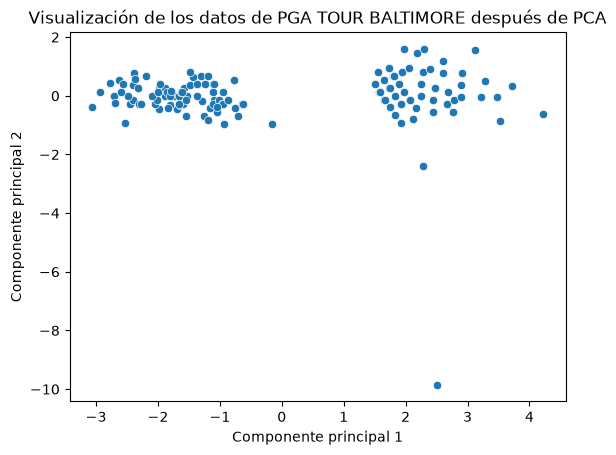

In [5]:
import seaborn as sns
sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1])
plt.title("Visualización de los datos de PGA TOUR BALTIMORE después de PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

Text(0, 0.5, 'Componente principal 2')

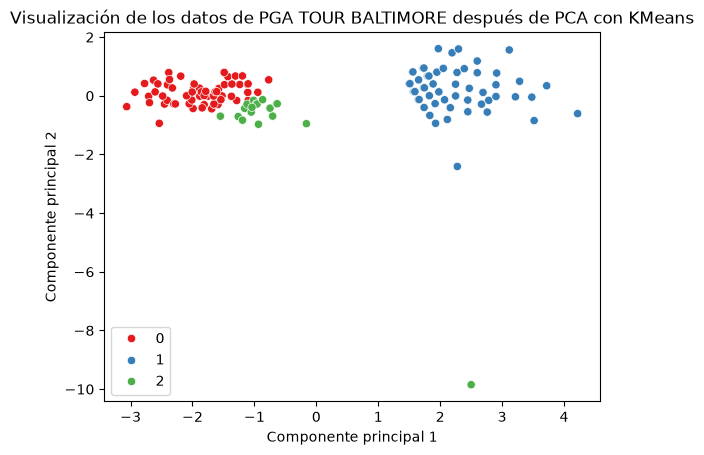

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(data_pca)

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1], hue=kmeans.labels_, palette='Set1')
plt.title("Visualización de los datos de PGA TOUR BALTIMORE después de PCA con KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

In [7]:
kmeans.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0,
       2, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 2,
       0, 0, 2, 0, 0, 2, 2, 2, 2, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2],
      dtype=int32)

In [8]:
data_clusters = pd.concat(
    [data_pga.reset_index(drop=True), pd.DataFrame(kmeans.labels_, columns=["Cluster"])],
    axis=1
)

display(data_clusters.head(80))

,posicion,score,ronda1,ronda2,ronda3,ronda4,Cluster
0,1,-26,66,67,64,61,0
1,2,-24,67,67,65,61,0
2,3,-23,69,62,65,65,0
3,4,-23,65,62,65,69,0
4,5,-21,68,66,69,60,0
...,...,...,...,...,...,...,...
75,76,0,67,71,75,71,0
76,77,-2,74,66,0,0,1
77,78,-2,73,67,0,0,1
78,79,-2,72,68,0,0,1


In [9]:
data_clusters.dtypes

data_clusters['score'] = data_clusters['score'].astype(float)

data_clusters.dtypes

posicion      int64
score       float64
ronda1        int64
ronda2        int64
ronda3        int64
ronda4        int64
Cluster       int32
dtype: object

In [10]:
data_clusters.groupby('Cluster').mean()

,posicion,score,ronda1,ronda2,ronda3,ronda4
Cluster,,,,,,
0,33.033898,-14.745763,67.406780,68.186441,66.644068,67.016949
1,104.000000,2.109091,71.509091,72.254545,0.000000,0.000000
2,61.611111,-8.277778,71.222222,63.555556,64.166667,64.944444


<Axes: ylabel='Cluster'>

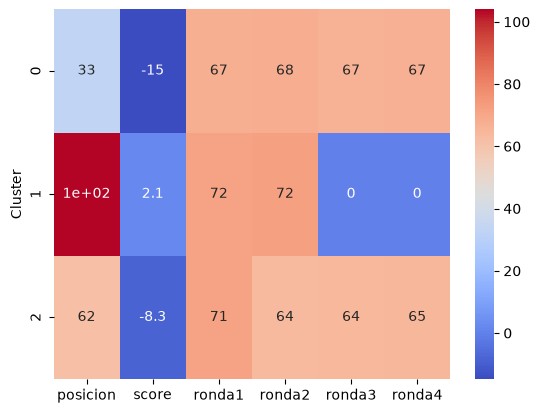

In [11]:
sns.heatmap(data_clusters.groupby('Cluster').mean(), annot=True, cmap='coolwarm')

In [12]:
data_clusters.to_csv("BALTIMORE.csv", index=False)